## Zadanie 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("stroke_zaj1.csv", decimal=",", sep=";")
data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Male,80,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
2,Female,49,0,0,Yes,Private,NaN,171.23,34.4,smokes,1
3,Female,79,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
4,Male,81,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


In [20]:
# Sprawdzenie typów danych i ile jest obserwacji
print(data.shape)
data.info()

(612, 11)
<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             612 non-null    str    
 1   age                612 non-null    int64  
 2   hypertension       612 non-null    int64  
 3   heart_disease      612 non-null    int64  
 4   ever_married       612 non-null    str    
 5   work_type          557 non-null    str    
 6   Residence_type     552 non-null    str    
 7   avg_glucose_level  568 non-null    float64
 8   bmi                549 non-null    float64
 9   smoking_status     612 non-null    str    
 10  stroke             612 non-null    int64  
dtypes: float64(2), int64(4), str(5)
memory usage: 52.7 KB


In [3]:
# Podstawowe statystyki dla zmiennych liczbowych
data.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,612.000000,612.000000,612.000000,568.000000,549.000000,612.000000
mean,52.632353,0.158497,0.096405,116.235352,30.420036,0.341503
std,20.709916,0.365505,0.295388,53.497575,7.044442,0.474602
min,5.000000,0.000000,0.000000,55.390000,14.600000,0.000000
25%,39.000000,0.000000,0.000000,78.785000,25.600000,0.000000
50%,54.000000,0.000000,0.000000,95.925000,29.300000,0.000000
75%,70.000000,0.000000,0.000000,129.505000,34.400000,1.000000
max,82.000000,1.000000,1.000000,271.740000,56.600000,1.000000


In [21]:
# Sprawdzenie wartości i liczebności w kolumnach kategorycznych
for kolumna in data.select_dtypes(include="object").columns:
    print("\\n", kolumna)
    print(data[kolumna].value_counts(dropna=False))

\n gender
gender
Female    355
Male      257
Name: count, dtype: int64
\n ever_married
ever_married
Yes    480
No     132
Name: count, dtype: int64
\n work_type
work_type
Private          340
Self-employed    112
Govt_job          77
NaN               55
children          28
Name: count, dtype: int64
\n Residence_type
Residence_type
Urban    289
Rural    263
NaN       60
Name: count, dtype: int64
\n smoking_status
smoking_status
never smoked       238
formerly smoked    141
Unknown            123
smokes             110
Name: count, dtype: int64


C:\Users\Kasia\AppData\Local\Temp\ipykernel_37496\1929372950.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for kolumna in data.select_dtypes(include="object").columns:


In [22]:
# Sprawdzenie, w których kolumnach są braki danych
braki = data.isna().sum()
print(braki[braki > 0])

work_type            55
Residence_type       60
avg_glucose_level    44
bmi                  63
dtype: int64


Brakujące wartości można uzupełnić na kilka sposobów. Dla zmiennych liczbowych porównuję średnią i medianę, a dla zmiennych kategorycznych najczęściej występującą wartość. Mediana jest mniej wrażliwa na wartości skrajne niż średnia.

In [23]:
# Zapisanie statystyk przed uzupełnieniem braków
kolumny_liczbowe = data.select_dtypes(include=np.number).columns.drop("stroke")
statystyki_przed = data[kolumny_liczbowe].agg(["mean", "median", "std"]).T
statystyki_przed

,mean,median,std
age,52.632353,54.000,20.709916
hypertension,0.158497,0.000,0.365505
heart_disease,0.096405,0.000,0.295388
avg_glucose_level,116.235352,95.925,53.497575
bmi,30.420036,29.300,7.044442


In [24]:
# Uzupełnienie braków w kopiach danych, żeby móc porównać różne metody
data_srednia = data.copy()
data_mediana = data.copy()
data_moda = data.copy()

for kolumna in kolumny_liczbowe:
    data_srednia[kolumna] = data_srednia[kolumna].fillna(data_srednia[kolumna].mean())
    data_mediana[kolumna] = data_mediana[kolumna].fillna(data_mediana[kolumna].median())

kolumny_kategoryczne = data.select_dtypes(include="object").columns
for kolumna in kolumny_kategoryczne:
    data_moda[kolumna] = data_moda[kolumna].fillna(data_moda[kolumna].mode()[0])

C:\Users\Kasia\AppData\Local\Temp\ipykernel_37496\2519548114.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kolumny_kategoryczne = data.select_dtypes(include="object").columns


In [25]:
# Porównanie statystyk przed uzupełnieniem braków i po zastosowaniu średniej oraz mediany
porownanie = pd.concat({
    "Przed": data[kolumny_liczbowe].agg(["mean", "median", "std"]).T,
    "Średnia": data_srednia[kolumny_liczbowe].agg(["mean", "median", "std"]).T,
    "Mediana": data_mediana[kolumny_liczbowe].agg(["mean", "median", "std"]).T
}, axis=1)

porownanie.round(2)

Przed               Średnia               Mediana         \
                     mean median    std    mean median    std    mean median   
age                 52.63  54.00  20.71   52.63  54.00  20.71   52.63  54.00   
hypertension         0.16   0.00   0.37    0.16   0.00   0.37    0.16   0.00   
heart_disease        0.10   0.00   0.30    0.10   0.00   0.30    0.10   0.00   
avg_glucose_level  116.24  95.92  53.50  116.24  98.60  51.54  114.78  95.92   
bmi                 30.42  29.30   7.04   30.42  30.15   6.67   30.30  29.30   

                          
                     std  
age                20.71  
hypertension        0.37  
heart_disease       0.30  
avg_glucose_level  51.80  
bmi                 6.68

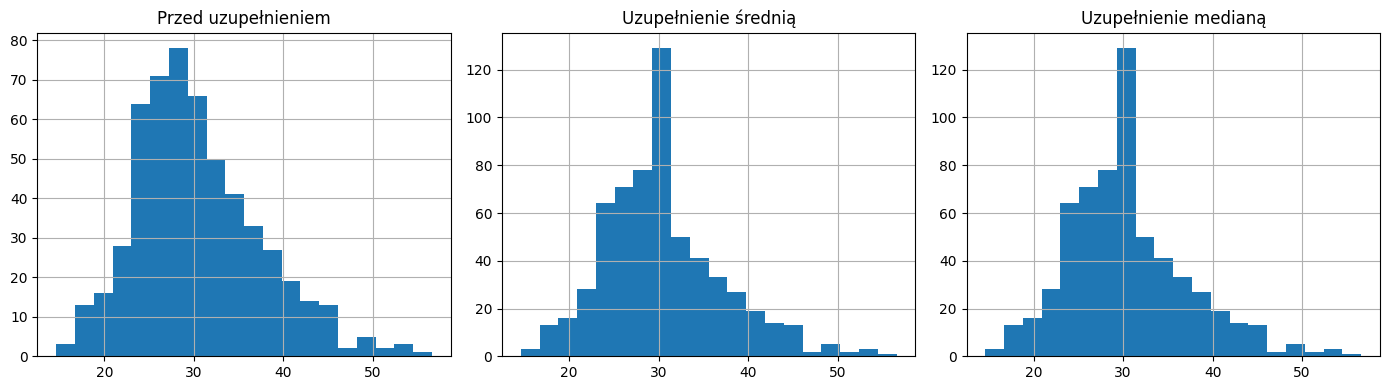

In [26]:
# Rozkład przykładowej zmiennej przed uzupełnieniem braków i po nim
kolumna = "bmi"

fig, osie = plt.subplots(1, 3, figsize=(14, 4))
data[kolumna].dropna().hist(ax=osie[0], bins=20)
osie[0].set_title("Przed uzupełnieniem")
data_srednia[kolumna].hist(ax=osie[1], bins=20)
osie[1].set_title("Uzupełnienie średnią")
data_mediana[kolumna].hist(ax=osie[2], bins=20)
osie[2].set_title("Uzupełnienie medianą")
plt.tight_layout()
plt.show()

Na wykresach widać, że uzupełnianie braków może zmienić rozkład zmiennej. Wartości uzupełnione średnią lub medianą skupiają się w jednym miejscu, przez co zmieniają się m.in. średnia, odchylenie standardowe i kształt rozkładu. Mediana jest zwykle lepszym wyborem, gdy rozkład jest skośny albo występują wartości skrajne. Dla zmiennych kategorycznych uzupełnienie dominantą zwiększa liczebność najczęściej występującej kategorii.

In [27]:
# Kodowanie zmiennych kategorycznych na wartości liczbowe, aby można było wykorzystać je w modelu
data_model = data.copy()

data_model["gender"] = data_model["gender"].map({"Male": 1, "Female": 0})
data_model["ever_married"] = data_model["ever_married"].map({"Yes": 1, "No": 0})

data_model = pd.get_dummies(
    data_model,
    columns=["work_type", "Residence_type", "smoking_status"],
    dtype=int
)

data_model.head()

,gender,age,hypertension,heart_disease,ever_married,avg_glucose_level,bmi,stroke,work_type_Govt_job,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1,67,0,1,1,228.69,36.6,1,0,1,0,0,0,1,0,1,0,0
1,1,80,0,1,1,105.92,32.5,1,0,1,0,0,1,0,0,0,1,0
2,0,49,0,0,1,171.23,34.4,1,0,1,0,0,0,0,0,0,0,1
3,0,79,1,0,1,174.12,24.0,1,0,0,1,0,1,0,0,0,1,0
4,1,81,0,0,1,186.21,29.0,1,0,1,0,0,0,1,0,1,0,0


Podział na zbiór uczący i testowy pozwala ocenić, jak model radzi sobie z danymi, których nie widział podczas uczenia. Zbiór uczący służy do dopasowania modelu, a testowy do sprawdzenia jakości jego przewidywań. Używam podziału 80/20. Parametr `stratify` pomaga zachować podobny udział obu klas `stroke` w obu zbiorach.

In [11]:
from sklearn.model_selection import train_test_split

X = data_model.drop(columns=["stroke"])
y = data_model["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Zbiór uczący:", X_train.shape)
print("Zbiór testowy:", X_test.shape)
print("\\nUdział klas w całym zbiorze:")
print(y.value_counts(normalize=True).sort_index())
print("\\nUdział klas w zbiorze uczącym:")
print(y_train.value_counts(normalize=True).sort_index())
print("\\nUdział klas w zbiorze testowym:")
print(y_test.value_counts(normalize=True).sort_index())

Zbiór uczący: (489, 17)
Zbiór testowy: (123, 17)
\nUdział klas w całym zbiorze:
stroke
0    0.658497
1    0.341503
Name: proportion, dtype: float64
\nUdział klas w zbiorze uczącym:
stroke
0    0.658487
1    0.341513
Name: proportion, dtype: float64
\nUdział klas w zbiorze testowym:
stroke
0    0.658537
1    0.341463
Name: proportion, dtype: float64


Macierz błędu (confusion matrix) pokazuje, ile obserwacji zostało sklasyfikowanych poprawnie i ile razy model pomylił klasy. W klasyfikacji binarnej można na jej podstawie wyróżnić prawdziwie dodatnie (TP), prawdziwie ujemne (TN), fałszywie dodatnie (FP) i fałszywie ujemne (FN).

- **Dokładność (accuracy)** – udział wszystkich poprawnych przewidywań.
- **Czułość (recall)** – udział poprawnie wykrytych przypadków udaru wśród wszystkich osób, które miały udar.
- **Specyficzność** – udział poprawnie rozpoznanych osób bez udaru wśród wszystkich osób bez udaru.
- **F1** – średnia harmoniczna precyzji i czułości.

Nie ma jednej miary, która zawsze jest najważniejsza. W tym zadaniu szczególnie warto sprawdzać czułość, bo niski wynik oznacza, że model nie wykrywa wielu przypadków udaru. Sama dokładność może być myląca, ponieważ klasy są niezrównoważone.

## Zadanie 2

Metoda k-najbliższych sąsiadów (KNN) szuka w zbiorze uczącym `k` obserwacji najbardziej podobnych do nowej obserwacji. Klasa jest wybierana na podstawie głosowania sąsiadów. Małe `k` może powodować nadmierne dopasowanie do danych uczących, a duże `k` może zbyt mocno uśredniać różnice między klasami.

W KNN standaryzacja jest ważna, ponieważ metoda opiera się na odległościach. Bez niej zmienne o większej skali, np. poziom glukozy, mogłyby mieć nieproporcjonalnie duży wpływ na wynik. Zmienne kategoryczne można wykorzystać po zakodowaniu ich, np. metodą one-hot encoding. Wtedy każda kategoria ma własną kolumnę.

In [28]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    recall_score, precision_score, f1_score
)

# Uzupełnienie braków medianą i standaryzuję dane.
# Oba kroki są w pipeline, więc parametry są wyznaczane tylko na zbiorze uczącym.
model_knn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

model_knn.fit(X_train, y_train)
y_pred = model_knn.predict(X_test)

print("Macierz błędu:")
print(confusion_matrix(y_test, y_pred))
print("\\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred, zero_division=0))

Macierz błędu:
[[65 16]
 [23 19]]
\nRaport klasyfikacji:
              precision    recall  f1-score   support

           0       0.74      0.80      0.77        81
           1       0.54      0.45      0.49        42

    accuracy                           0.68       123
   macro avg       0.64      0.63      0.63       123
weighted avg       0.67      0.68      0.68       123



In [29]:
# Obliczania specyficzności
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

dokladnosc = accuracy_score(y_test, y_pred)
czulosc = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
specyficznosc = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

print(f"Dokładność: {dokladnosc:.3f}")
print(f"Czułość: {czulosc:.3f}")
print(f"Specyficzność: {specyficznosc:.3f}")
print(f"F1: {f1:.3f}")

Dokładność: 0.683
Czułość: 0.452
Specyficzność: 0.802
F1: 0.494


### KNN z ważeniem odległości

W tej wersji sąsiedzi położeni bliżej obserwacji mają większy wpływ na decyzję modelu. Tak jak w przykładzie z zajęć, ustawiam `weights='distance'`. Idealny wynik na zbiorze uczącym nie musi oznaczać, że model będzie równie dobrze działał na nowych danych, dlatego najważniejszy jest wynik na zbiorze testowym.

In [30]:
# Budowa KNN, w którym wpływ sąsiadów zależy od ich odległości
model_weighted_knn = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])

model_weighted_knn.fit(X_train, y_train)

# Prognoza
y_train_pred_weighted_knn = model_weighted_knn.predict(X_train)
y_test_pred_weighted_knn = model_weighted_knn.predict(X_test)

# Macierze pomyłek: najpierw klasa rzeczywista, potem przewidywana
print("Zbiór uczący:")
print(confusion_matrix(y_train, y_train_pred_weighted_knn, labels=[0, 1]))

print("\\nZbiór testowy:")
print(confusion_matrix(y_test, y_test_pred_weighted_knn, labels=[0, 1]))

print("\\nRaport klasyfikacji dla zbioru testowego:")
print(classification_report(y_test, y_test_pred_weighted_knn, labels=[0, 1], zero_division=0))


Zbiór uczący:
[[322   0]
 [  0 167]]
\nZbiór testowy:
[[63 18]
 [22 20]]
\nRaport klasyfikacji dla zbioru testowego:
              precision    recall  f1-score   support

           0       0.74      0.78      0.76        81
           1       0.53      0.48      0.50        42

    accuracy                           0.67       123
   macro avg       0.63      0.63      0.63       123
weighted avg       0.67      0.67      0.67       123



### Regresja logistyczna

Regresja logistyczna to kolejna metoda klasyfikacji. Zamiast głosowania sąsiadów wyznacza prawdopodobieństwo przynależności do klasy. Używam tego samego podziału na zbiór uczący i testowy, a braki danych i standaryzację umieszczam w `Pipeline`, żeby parametry przygotowania danych były wyznaczane wyłącznie na zbiorze uczącym.

In [15]:
from sklearn.linear_model import LogisticRegression

model_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42))
])

model_lr.fit(X_train, y_train)

# Predykcja klas na zbiorze testowym
y_pred_lr = model_lr.predict(X_test)
print("Pierwsze przewidziane klasy:")
print(y_pred_lr[:10])

# Prawdopodobieństwa przynależności do klas
y_prob_lr = model_lr.predict_proba(X_test)
print("\\nKolejność klas:", model_lr.named_steps["logreg"].classes_)
print("Pierwsze prawdopodobieństwa:")
print(y_prob_lr[:10])

# Ocena jakości klasyfikacji
print("\\nMacierz pomyłek:")
print(confusion_matrix(y_test, y_pred_lr, labels=[0, 1]))

print("\\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_lr, labels=[0, 1], zero_division=0))


Pierwsze przewidziane klasy:
[0 0 0 1 1 1 1 0 0 0]
\nKolejność klas: [0 1]
Pierwsze prawdopodobieństwa:
[[0.95903379 0.04096621]
 [0.61590044 0.38409956]
 [0.9587763  0.0412237 ]
 [0.26447698 0.73552302]
 [0.44780642 0.55219358]
 [0.38730799 0.61269201]
 [0.09569192 0.90430808]
 [0.77963632 0.22036368]
 [0.78383879 0.21616121]
 [0.8994942  0.1005058 ]]
\nMacierz pomyłek:
[[64 17]
 [15 27]]
\nRaport klasyfikacji:
              precision    recall  f1-score   support

           0       0.81      0.79      0.80        81
           1       0.61      0.64      0.63        42

    accuracy                           0.74       123
   macro avg       0.71      0.72      0.71       123
weighted avg       0.74      0.74      0.74       123



In [31]:
# Obliczenie podstawowych miar jakości regresji logistycznej
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_lr, labels=[0, 1]).ravel()

dokladnosc_lr = accuracy_score(y_test, y_pred_lr)
czulosc_lr = recall_score(y_test, y_pred_lr, pos_label=1, zero_division=0)
specyficznosc_lr = tn / (tn + fp) if (tn + fp) > 0 else 0
f1_lr = f1_score(y_test, y_pred_lr, pos_label=1, zero_division=0)

print(f"Dokładność: {dokladnosc_lr:.3f}")
print(f"Czułość: {czulosc_lr:.3f}")
print(f"Specyficzność: {specyficznosc_lr:.3f}")
print(f"F1: {f1_lr:.3f}")


Dokładność: 0.740
Czułość: 0.643
Specyficzność: 0.790
F1: 0.628


Domyślnie model przypisuje klasę na podstawie progu 0,5. Próg można zmienić, jeśli ważniejsze jest wykrywanie większej liczby przypadków udaru. Niższy próg zwykle zwiększa czułość, ale może też zwiększyć liczbę fałszywie dodatnich przewidywań. Próg należy dobierać na danych walidacyjnych, a nie na podstawie samego zbioru testowego.

In [32]:
# Pobranie prawdopodobieństwa klasy 1, czyli wystąpienia udaru
klasy_lr = model_lr.named_steps["logreg"].classes_
indeks_udaru = list(klasy_lr).index(1)
p_udaru = y_prob_lr[:, indeks_udaru]

# Przykładowy próg odcięcia
prog = 0.3
y_pred_prog = (p_udaru >= prog).astype(int)

print("Próg odcięcia:", prog)
print("Macierz pomyłek:")
print(confusion_matrix(y_test, y_pred_prog, labels=[0, 1]))
print("\\nRaport klasyfikacji:")
print(classification_report(y_test, y_pred_prog, labels=[0, 1], zero_division=0))


Próg odcięcia: 0.3
Macierz pomyłek:
[[53 28]
 [ 8 34]]
\nRaport klasyfikacji:
              precision    recall  f1-score   support

           0       0.87      0.65      0.75        81
           1       0.55      0.81      0.65        42

    accuracy                           0.71       123
   macro avg       0.71      0.73      0.70       123
weighted avg       0.76      0.71      0.71       123



Sprawdzam kilka wartości `k`. Wykorzystuję nieparzyste wartości, żeby w prostym głosowaniu przy dwóch klasach zmniejszyć ryzyko remisu. Nie oznacza to jednak, że `k` zawsze musi być nieparzyste. Najlepszą wartość dobiera się na podstawie wyników walidacji, a nie tylko jednego podziału.

In [33]:
wyniki = []

# Testróżnych wartości k i porównanie wyników na zbiorze testowym
for k in range(1, 32, 2):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()

    wyniki.append({
        "k": k,
        "Dokładność": accuracy_score(y_test, pred),
        "Czułość": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "Specyficzność": tn / (tn + fp) if (tn + fp) > 0 else 0,
        "F1": f1_score(y_test, pred, pos_label=1, zero_division=0)
    })

wyniki_knn = pd.DataFrame(wyniki)
wyniki_knn.round(3)

,k,Dokładność,Czułość,Specyficzność,F1
0,1,0.659,0.548,0.716,0.523
1,3,0.618,0.405,0.728,0.420
2,5,0.683,0.452,0.802,0.494
3,7,0.675,0.381,0.827,0.444
4,9,0.691,0.357,0.864,0.441
5,11,0.715,0.405,0.877,0.493
6,13,0.691,0.310,0.889,0.406
7,15,0.707,0.333,0.901,0.438
8,17,0.699,0.333,0.889,0.431
9,19,0.715,0.333,0.914,0.444


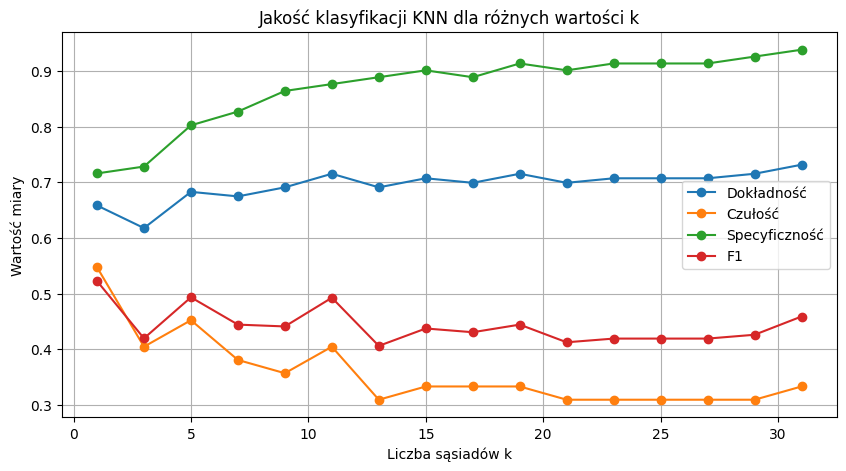

In [34]:
# Porównanie, jak zmieniają się miary jakości wraz ze zmianą k
wyniki_knn.plot(x="k", y=["Dokładność", "Czułość", "Specyficzność", "F1"],
                marker="o", figsize=(10, 5))
plt.title("Jakość klasyfikacji KNN dla różnych wartości k")
plt.xlabel("Liczba sąsiadów k")
plt.ylabel("Wartość miary")
plt.grid(True)
plt.show()

Wyniki dla różnych wartości `k` mogą się różnić. Zwykle nie da się wybrać najlepszego parametru wyłącznie na podstawie dokładności, szczególnie gdy przypadków udaru jest znacznie mniej niż przypadków bez udaru. Warto jednocześnie patrzeć na czułość, specyficzność i F1. W praktyce `k` najlepiej dobierać na zbiorze walidacyjnym lub przez walidację krzyżową, a zbiór testowy zostawić do końcowej oceny modelu.

## Zadanie 3